# Project 3 - Hypothesis Testing

Git Commit History can be found at https://github.com/vigneshK0404/Data_Science_Projects.git

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import Bounds, minimize
from scipy.stats import cauchy, expon, chi2, truncate
import random

In [2]:
#CONSTANTS
E0 = 205
G = 28
Eb = 100

## 1 . Choose File

In [3]:
data_path = "data/Project3_Set3.txt"
df = pd.read_csv(data_path, header=None).astype(float)
E = np.array(df).squeeze()

## 2 . Count Photons

In [4]:
N_photons = len(df)
print(f"Number of total events : {N_photons}")

Number of total events : 340


## 3. Photon Energy Distribution

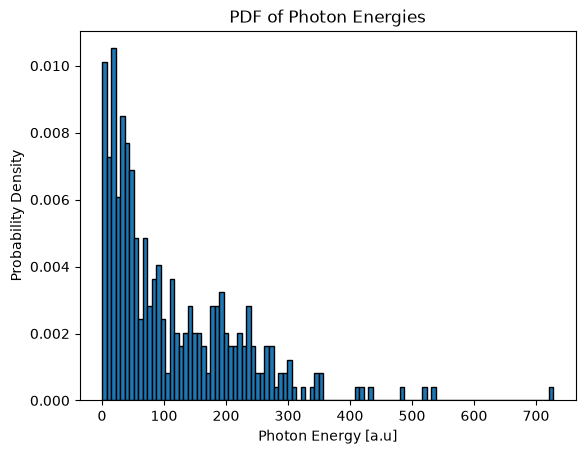

In [5]:
plt.hist(E,bins=100,edgecolor="k",density=True)
plt.xlabel("Photon Energy [a.u]")
plt.ylabel("Probability Density")
plt.title("PDF of Photon Energies")
plt.show()

## 4 . MLE ns Best Fit 

In [6]:
def signal(ns, E) -> np.array:
    return (ns/N_photons)*cauchy.pdf(E, loc=E0, scale=G)

def background(nb, E) -> np.array:
    return (nb/N_photons)*expon.pdf(E, loc=0, scale=Eb)

def complete_pdf(x, E):
    ns = x
    return signal(ns,E) + background(N_photons - ns,E)

def loglikelihood_total(x, E) -> float:
    return -2*np.sum(np.log(complete_pdf(x,E)), axis=-1)

def loglikelihood_bg(nb,E)->float:
    return -2*np.sum(np.log(nb/N_photons) - np.log(Eb) - E/Eb, axis=-1)

def loglikelihood_ratio(x,E):
    return -loglikelihood_total(x,E) + loglikelihood_bg(N_photons,E)

In [8]:
ns_bound = [0,N_photons]
ns_init = N_photons/2
init_vals = [ns_init]
bound_arr = [ns_bound]

In [9]:
min_params = minimize(loglikelihood_total, x0=init_vals, args=E ,method="SLSQP", bounds=bound_arr)
ns = min_params.x.item()
nb = N_photons - ns
print(f"N_signal: {round(ns)} \nN_background:{round(nb)}")

N_signal: 33 
N_background:307


## 5 . Overlaid Histogram

In [10]:
Energy_centers = np.linspace(0,np.max(E),N_photons)
pred_total = complete_pdf(min_params.x,Energy_centers)
pred_signal = signal(ns,Energy_centers)
pred_background = background(nb, Energy_centers)

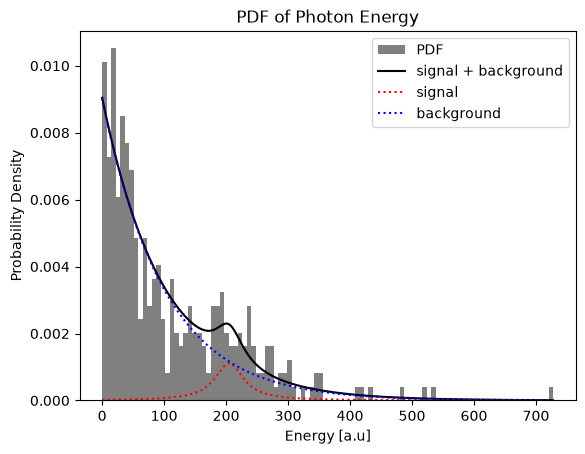

In [11]:
plt.hist(E, bins=100, density=True, label="PDF", color="grey")
plt.plot(Energy_centers, pred_total,color="black", label="signal + background")
plt.plot(Energy_centers, pred_signal,linestyle="dotted",color="red", label="signal")
plt.plot(Energy_centers, pred_background,linestyle="dotted" ,color="blue", label="background")
plt.xlabel("Energy [a.u]")
plt.ylabel("Probability Density")
plt.title("PDF of Photon Energy")
plt.legend()
plt.show()

## 6 . Test Statistic

In [12]:
TS = loglikelihood_ratio(min_params.x,E)
print(f"Test Statistic at best fit : {TS.item() :.3f}")

Test Statistic at best fit : 11.164


## 7 . Null Hypothesis Simulation

In [13]:
N_simul = 10000
E_simulated = np.random.exponential(scale=Eb, size=(N_simul, N_photons))

## 8 . MLE simulation ns Estimation

In [14]:
ns_array = []
for i in range(N_simul):
    E_i = E_simulated[i]
    min_params_i = minimize(loglikelihood_total, x0=init_vals, args=E_i ,method="SLSQP", bounds=bound_arr)
    ns_array.append(min_params_i.x)

In [15]:
ns_array = np.array(ns_array)
ns_array_T = ns_array.reshape(-1,1)

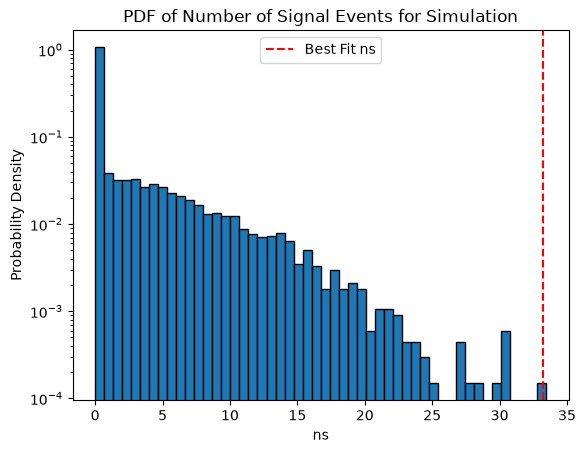

In [16]:
plt.hist(ns_array_T,bins=50,edgecolor="k",density=True)
plt.xlabel("ns")
plt.ylabel("Probability Density")
plt.title("PDF of Number of Signal Events for Simulation")
plt.axvline(x=ns, color='red', linestyle='--', label='Best Fit ns')
plt.yscale('log')
plt.legend(loc="upper center")
plt.show()

## 9 . TS Calculation

In [17]:
TS_null = loglikelihood_ratio(ns_array_T, E_simulated)
TS_above = np.percentile(TS_null,99)

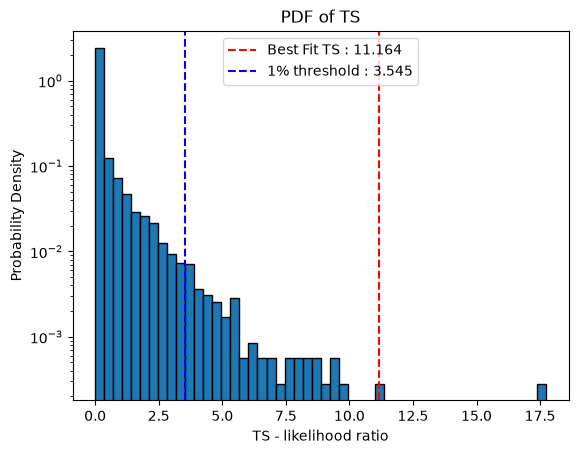

In [32]:
plt.hist(TS_null,bins=50,edgecolor="k",density=True)
plt.xlabel("TS - likelihood ratio")
plt.ylabel("Probability Density")
plt.title("PDF of TS")
plt.yscale('log')
plt.axvline(x=TS.item(), color='red', linestyle='--', label=f'Best Fit TS : {TS:.3f}')
plt.axvline(x=TS_above, color='blue', linestyle='--', label=f'1% threshold : {TS_above :.3f}')
plt.legend(loc="upper center")
plt.show()

In [35]:
num_obs = np.sum(TS_null > TS)
num_obs/N_simul

np.float64(0.0001)

## 10 . Hypothesis test

If there truly was no signal, i.e there was no signal and H0 is correct. Then, according to the plot above, out of 10000 experiments 100 have a larger TS value the threshold determined. But since the observed TS value is much larger than the cut-off and only 1 expriment in 10000 exceeded the TS_bestfit. We have enough evidence to reject the null hypothesis. 

$p = \frac{1}{10000} = 0.0001$

## 11 . Simulation Size

It comes down to how much statistics that is available that are over the 1% accepted type-1 error. If you have only 100 experiments then on average you would only have 1 experiment that incorrectly rejects H0, which means you cannot make a statement about how large TS_best fit is relative to TS_crit. 10,000,000 experiements would solve the statistics problem but is not computationally feasible


For 100 experiments, and a 5$\sigma$ significance.
$P(Z >= 5) = 2.87e-7$
$\frac{100}{2.87e-7} = 3.49e8$ experiments

Yes I could see a signal

## 12 . ROC Curve

In [7]:
def roc_curve(ts_null, ts_alt):
    '''For every possible threshold t (every simulated value), the fraction of null and of
    alternative experiments with a test statistic above t:
    P(type I error) = P(TS > t | H0) and power = P(TS > t | H1).'''
    t = np.sort(np.concatenate([ts_null, ts_alt]))[::-1]
    alpha = 1 - np.searchsorted(np.sort(ts_null), t, side='right') / len(ts_null)
    power = 1 - np.searchsorted(np.sort(ts_alt), t, side='right') / len(ts_alt)
    return alpha, power

def auc_from_samples(ts_null, ts_alt):
    '''The same area computed directly from the samples: AUC = P(TS_alt > TS_null),
    the probability that a random H1 experiment has a larger TS than a random H0 experiment.'''
    n_null_below = np.searchsorted(np.sort(ts_null), ts_alt, side='left')
    return np.mean(n_null_below) / len(ts_null)

In [19]:
def filtered_cauchy(loc, scale, size):
    signal_list = cauchy.rvs(loc=E0, scale=G, size=size)

    while np.any(signal_list < 0):
        mask = signal_list < 0 
        signal_list[mask] = cauchy.rvs(
        loc=E0, scale=G, size=np.sum(mask)
        )

    return signal_list

In [26]:
ns_variant = ns + 15
ns_list = [ns, ns_variant]

TS_list = []

for ns_true in ns_list:
    signal_list = filtered_cauchy(loc=E0, scale=G, size=(N_simul,round(ns_true)))
    background_list = np.random.exponential(scale=Eb, size=(N_simul, N_photons-round(ns_true)))
    sig_bg = np.concatenate((signal_list,background_list),axis=1)

    ns_array_h1 = []
    for i in range(N_simul):
        E_i = sig_bg[i]
        min_params_i = minimize(loglikelihood_total, x0=init_vals, args=(E_i,) ,method="SLSQP", bounds=bound_arr)
        ns_array_h1.append(min_params_i.x)

    ns_array_T_h1 = np.array(ns_array_h1).reshape(-1,1)
    TS_array_h1 = loglikelihood_ratio(ns_array_T_h1, sig_bg)
    TS_list.append(TS_array_h1)

TS_alt_1, TS_alt_2 = TS_list

In [27]:
alpha_1, power_1 = roc_curve(TS_null,TS_alt_1)
alpha_2, power_2 = roc_curve(TS_null, TS_alt_2)
auc1 = auc_from_samples(TS_null, TS_alt_1)
auc2 = auc_from_samples(TS_null, TS_alt_2)

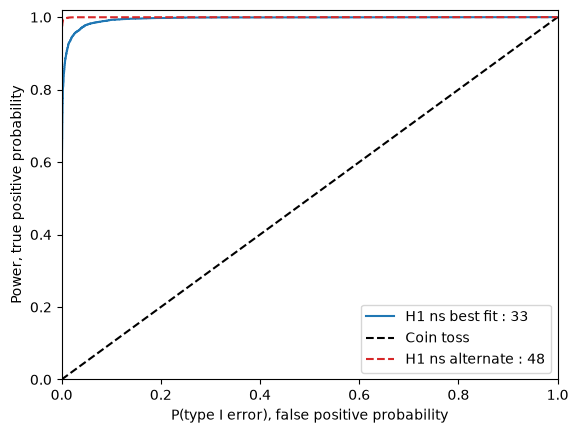

In [28]:
plt.plot(alpha_1, power_1, label=f'H1 ns best fit : {round(ns)}')
plt.plot([0, 1], [0, 1], 'k--', label='Coin toss')
plt.plot(alpha_2, power_2, '--', color='C3', label=f'H1 ns alternate : {round(ns_variant)}')
plt.xlabel('P(type I error), false positive probability')
plt.ylabel('Power, true positive probability')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc='lower right')
plt.show()

In [29]:
print(f"AUC_best_fit : {auc1 :.4f}")
print(f"AUC_alternate_fit : {auc2 :.4f}")

AUC_best_fit : 0.9946
AUC_alternate_fit : 0.9999


In [38]:
print("I spent 10 hours on this project")

I spent 10 hours on this project
